# 03 — GMM parameter investigation

**Replication of:** *Presence-absence estimation in audio recordings of tropical frog communities*
(Estrella Terneux, Nicolalde, Nicolalde & Merino-Viteri, arXiv:1901.02495)

## 1. Objective

Notebook 02 produced frame-level modified cepstral features from labelled calls. This notebook
carries out the modelling experiment of Sections **3.5, 3.6 and 4.1** of the article:

**processed call features → one GMM per species → call-level likelihood scoring → species prediction → per-species error → WER → parameter investigation**

The experiment follows the article's grid:

- training material per species: **6, 12 and 18 seconds**;
- Gaussian components: **2, 4, 8, 16, 32 and 64**;
- repeated random selections of the training calls (ten here).

`[PAPER]` The article draws its Figure 8 with **12 MFCC** features and reports its Table 2 with
**20 m-FCC** features. The features handed over by notebook 02 are 20 m-FCC, so this notebook
replicates the **Table 2 setting** and runs the whole 6/12/18-second grid on those features. The
plot it draws is a model-order grid on 20 m-FCC and is **not** a reproduction of Figure 8; no
12 MFCC features are built here.

This notebook stops at species identification. Verification of a detection against a threshold
and presence-absence estimation are not attempted here.

Every model and every score comes from `frog_presence.gmm`, which holds the procedure of the
article once so that every notebook that trains or scores a mixture uses the same one.

## 2. Load and validate the processed artefacts

**What this section asks, and why it matters.** Everything that follows rests on three files
written by notebook 02. If the frame matrix, the labels and the call table do not line up, every
error rate computed later would be meaningless, so they are checked against each other before
anything is modelled.

`features.npy` holds one row per frame, `labels.npy` the species code of each frame, and
`calls.csv` one row per call with the number of frames the call contributed.

In [1]:
# Every dependency, the display options and the location of the artefacts written by notebook 02.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from frog_presence.gmm import (
    MAX_ITER, CallCorpus, build_split, evaluate_models, fit_gmm, fit_species_models,
    initial_parameters, score_calls,
)

sns.set_theme(style="ticks")
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 40)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
PROCESSED_DIR = REPO_ROOT / "data" / "processed"

FEATURES_PATH = PROCESSED_DIR / "features.npy"
LABELS_PATH = PROCESSED_DIR / "labels.npy"
CALLS_PATH = PROCESSED_DIR / "calls.csv"

for path in (FEATURES_PATH, LABELS_PATH, CALLS_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.name}. Run notebooks/02_preprocessing.ipynb first.")

# Only the location relative to the repository: the absolute path is personal to whoever runs this.
print("Processed dir :", PROCESSED_DIR.relative_to(REPO_ROOT).as_posix())

Processed dir : data/processed


In [2]:
# Load the three files and check that they describe the same frames.
features = np.load(FEATURES_PATH)
labels = np.load(LABELS_PATH)
calls = pd.read_csv(CALLS_PATH)

print("features:", features.shape, features.dtype)
print("labels  :", labels.shape, labels.dtype)
print("calls   :", calls.shape)
display(calls.head())

required = {"code", "species", "wav", "seconds", "frames"}
missing = required - set(calls.columns)
if missing:
    raise ValueError(f"calls.csv is missing required columns: {sorted(missing)}")

assert features.ndim == 2
assert features.shape[1] == 20, f"Expected 20 features, got {features.shape[1]}"
assert len(features) == len(labels)
assert int(calls["frames"].sum()) == len(features)

print("Alignment checks passed.")

features: (136005, 20) float64
labels  : (136005,) <U3
calls   : (1461, 7)


,code,species,wav,recording,rate,seconds,frames
0,f01,Boana alfaroi,1101.WAV,0,44100,0.38,73
1,f01,Boana alfaroi,1101.WAV,0,44100,0.38,73
2,f01,Boana alfaroi,1101.WAV,0,44100,0.42,81
3,f01,Boana alfaroi,1101.WAV,0,44100,0.48,93
4,f01,Boana alfaroi,1101.WAV,0,44100,0.48,93


Alignment checks passed.


`[OBSERVED]` The frame matrix has **136005 rows and 20 columns**, the labels have one entry per row, and
the call table holds **1461 calls** whose frame counts add up to the 136005 frames. The three files
describe the same material.

## 3. Reconstruct complete calls

**What this section asks, and why it matters.** The unit that is separated between training and
validation is the **call**, never the frame: two frames of one call share their audio, so having
one on each side of a split would let the model be tested on what it was trained on. The frame
matrix has no call boundaries of its own, so they are rebuilt here from the per-call frame counts
and checked against the labels.

In [3]:
# Rebuild each call's frame range and check that every frame of a call carries that call's label.
corpus = CallCorpus(features, calls)
calls = corpus.calls

bad = []
for row in calls.itertuples(index=False):
    block = labels[row.frame_start:row.frame_stop]
    if len(block) != row.frames or not np.all(block == row.code):
        bad.append(row.call_id)

if bad:
    raise AssertionError(f"Call reconstruction failed for {len(bad)} calls: {bad[:5]}")

species_inventory = (
    calls.groupby(["code", "species"], as_index=False)
    .agg(calls=("call_id", "size"), seconds=("seconds", "sum"), frames=("frames", "sum"))
    .sort_values("code")
)
species_inventory["seconds"] = species_inventory["seconds"].round(2)

display(species_inventory)
print("Reconstructed calls:", len(calls))

,code,species,calls,seconds,frames
0,f01,Boana alfaroi,98,44.72,8650
1,f02,Dendropsophus bifurcus,99,41.72,8047
2,f03,Boana cinerascens,169,102.58,20009
3,f04,Pristimantis conspicillatus,186,77.94,15030
4,f05,Leptodactylus discodactylus,340,114.36,21852
5,f06,Osteocephalus fuscifacies,54,24.94,4826
6,f07,Boana lanciformis,101,57.84,11265
7,f08,Rhinella margaritifera,96,102.66,20244
8,f09,Dendropsophus parviceps,2,1.18,230
9,f10,Engystomops petersi,316,134.00,25852


Reconstructed calls: 1461


`[OBSERVED]` All **1461 calls** were reconstructed, and every frame inside each call's range carries
that call's species code: no call failed the check.

`[OBSERVED]` The species table shows how unequal the classes are. `f05` holds 340 calls and `f10`
316, while `f09` holds **2 calls and 1.18 seconds**.

## 4. Species usable in the experiment

**What this section asks, and why it matters.** The largest training condition takes 18 seconds
from each species and must leave calls over for validation. A species with less audio than that
cannot take part, and which ones those are decides what the results can be compared with.

`[PAPER]` Section 4.1 trains with 6, 12 and 18 seconds per species and validates on the rest.

*Decision, not stated in the article:* a species takes part when it holds more than 18 seconds of
calls. The list is derived from the data rather than written down.

In [4]:
# Fix the experimental grid and derive which species can support the largest training condition.
TRAINING_DURATIONS = (6, 12, 18)
N_COMPONENTS_GRID = (2, 4, 8, 16, 32, 64)
N_REPEATS = 10
BASE_SEED = 20260814

usable_inventory = species_inventory[species_inventory["seconds"] > max(TRAINING_DURATIONS)].copy()
USABLE_CODES = tuple(usable_inventory["code"])
excluded_inventory = species_inventory[~species_inventory["code"].isin(USABLE_CODES)].copy()

print("Usable species:", USABLE_CODES)
print("\nIncluded:")
display(usable_inventory)
print("\nExcluded:")
display(excluded_inventory)

Usable species: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')

Included:


,code,species,calls,seconds,frames
0,f01,Boana alfaroi,98,44.72,8650
1,f02,Dendropsophus bifurcus,99,41.72,8047
2,f03,Boana cinerascens,169,102.58,20009
3,f04,Pristimantis conspicillatus,186,77.94,15030
4,f05,Leptodactylus discodactylus,340,114.36,21852
5,f06,Osteocephalus fuscifacies,54,24.94,4826
6,f07,Boana lanciformis,101,57.84,11265
7,f08,Rhinella margaritifera,96,102.66,20244
9,f10,Engystomops petersi,316,134.00,25852



Excluded:


,code,species,calls,seconds,frames
8,f09,Dendropsophus parviceps,2,1.18,230


`[OBSERVED]` Nine species hold more than 18 seconds of calls and take part: `f01` to `f08` and `f10`.
`f09` is excluded, with 2 calls and 1.18 seconds.

`[PAPER]` Section 3.1 says nine species had enough material for the first experiments and that `f06`
was added separately for the testing stage. The article's nine therefore include `f09` and exclude
`f06`.

`[OBSERVED]` Here `f06` holds 24.94 seconds and qualifies, while `f09` does not. The two species
sets overlap in eight species and differ in one each way, so results are comparable to the article
in form but not in composition.

## 5. Select whole calls until the duration target is reached

**What this section asks, and why it matters.** The article trains on a fixed number of seconds
per species, but calls differ in length, so some rule has to say which calls make up those
seconds. The rule fixes how much audio each model really sees, and it has to be reproducible: the
same draw must come back every time.

`[PAPER]` The article selects 6, 12 or 18 seconds of calls for training and uses the remaining
calls for validation.

*Decision, not stated in the article:* the calls of a species are shuffled reproducibly and taken
in that order until their total duration reaches or exceeds the target. Calls are never cut to
hit the target exactly, and at least one call is always left for validation.

In [5]:
# Draw one split (12 s, first repeat), and check that it is reproducible and that no call is shared.
demo_train_ids, demo_validation_ids, demo_split = build_split(calls, USABLE_CODES, 12, 0, BASE_SEED)
display(demo_split[["code", "training_seconds_target", "training_seconds_actual",
                    "overshoot_seconds", "n_train_calls", "n_validation_calls"]])

demo_train_ids_2, demo_validation_ids_2, _ = build_split(calls, USABLE_CODES, 12, 0, BASE_SEED)
assert demo_train_ids == demo_train_ids_2
assert demo_validation_ids == demo_validation_ids_2
print("Split reproducibility check passed.")

for code_ in USABLE_CODES:
    assert not set(demo_train_ids[code_]) & set(demo_validation_ids[code_])
print("No call appears on both sides of the split.")

,code,training_seconds_target,training_seconds_actual,overshoot_seconds,n_train_calls,n_validation_calls
0,f01,12,12.10,0.10,26,72
1,f02,12,12.08,0.08,28,71
2,f03,12,12.60,0.60,19,150
3,f04,12,12.22,0.22,30,156
4,f05,12,12.18,0.18,35,305
5,f06,12,12.46,0.46,27,27
6,f07,12,12.54,0.54,23,78
7,f08,12,12.66,0.66,11,85
8,f10,12,12.22,0.22,29,287


Split reproducibility check passed.
No call appears on both sides of the split.


`[OBSERVED]` For the 12-second condition the selected calls last between 12.08 and 12.66 seconds per
species, an overshoot of **0.08 to 0.66 seconds**, since whole calls are taken. `f08` reaches its
target with only 11 calls, the fewest of any species, because its calls are long.

`[OBSERVED]` The validation sets differ greatly in size, from **27 calls** (`f06`) to **305 calls**
(`f05`). The same draw is returned when repeated, and no call appears on both sides of the split.

`[INFERENCE]` An overshoot of at most 0.66 seconds is small beside 12 seconds, so the rule changes the
training amount by a few percent and not by an amount that would matter for the comparison between
conditions.

## 6. Train one diagonal-covariance GMM per species

**What this section asks, and why it matters.** The article specifies how each mixture is
started, and EM only finds a local optimum, so where it starts shapes the model. This section
checks that the starting point handed to scikit-learn is the one the article describes, and that
the fit then runs to convergence instead of stopping on the iteration cap.

`[PAPER]` Maximum-likelihood estimation by EM, diagonal covariances, means initialised with
k-means++, initial covariances diagonal with the variance of each feature, uniform initial
weights.

The initial weights, means and precisions are supplied to `GaussianMixture` explicitly. A small
variance floor (`reg_covar`), the iteration cap and the tolerance are scikit-learn's defaults and
are **not** specified by the article.

In [6]:
# Show the starting point for one species and fit it, checking each element against the article.
demo_code, demo_components = USABLE_CODES[0], 4
X_demo = corpus.frames(demo_train_ids[demo_code])
weights0, means0, precisions0 = initial_parameters(X_demo, demo_components, seed=0)

print(f"{demo_code}: {len(X_demo)} training frames, {demo_components} components")
print("initial weights uniform      :", bool(np.allclose(weights0, 1 / demo_components)))
print("initial variance = data var  :", bool(np.allclose(1 / precisions0[0], X_demo.var(axis=0))))
print("same variance in every comp. :", bool((precisions0 == precisions0[0]).all()))
print("initial means shape          :", means0.shape)

demo_fit = fit_gmm(X_demo, demo_components, seed=0)
print("\nconverged:", bool(demo_fit.converged_), "| EM iterations:", demo_fit.n_iter_, "of", MAX_ITER)

f01: 2342 training frames, 4 components
initial weights uniform      : True
initial variance = data var  : True
same variance in every comp. : True
initial means shape          : (4, 20)

converged: True | EM iterations: 18 of 100


`[OBSERVED]` For `f01` with 4 components the model is started from **2342 training frames**, with
uniform initial weights and with every component's initial variance equal to the variance of the
data, as the article describes. The fit **converged after 18 of the 100 allowed EM iterations**.

## 7. Classify a complete call by average log-likelihood

**What this section asks, and why it matters.** A call has many frames, and the article needs one
decision per call. How the frame scores are combined decides which species wins, so the rule is
shown on a single call before it is applied to thousands.

`[PAPER]` Equation 9 assigns a call to the species whose model maximises the average frame
log-likelihood. Frames are therefore never classified independently.

In [7]:
# Fit a small model for every species and score one validation call under all of them.
demo_models = fit_species_models(corpus, demo_train_ids, n_components=2,
                                 target_seconds=12, repeat=0, base_seed=BASE_SEED)
example_true = USABLE_CODES[0]
example_id = demo_validation_ids[example_true][0]
example_scores = dict(zip(demo_models, score_calls(demo_models, corpus, [example_id])[0]))
example_pred = max(example_scores, key=example_scores.get)

print("Call      :", example_id)
print("True code :", example_true)
print("Prediction:", example_pred)
display(pd.Series(example_scores, name="mean_log_likelihood").sort_values(ascending=False).to_frame())

Call      : call_0000
True code : f01
Prediction: f01


,mean_log_likelihood
f01,-40.293595
f05,-47.851856
f06,-48.888467
f03,-49.016555
f02,-49.662071
f10,-52.145369
f04,-52.196830
f07,-55.742525
f08,-68.529623


`[OBSERVED]` The first validation call of `f01` is assigned to `f01`, with a mean log-likelihood of
**-40.29** against **-47.85** for the runner-up (`f05`). The score is an average over the call's
frames, so calls of different lengths are comparable.

## 8. Per-species error and WER

**What this section asks, and why it matters.** The species are very unbalanced, from tens of
validation calls to hundreds. Counting every call equally would let the largest species decide the
result, so the article averages the species' own error rates instead.

`[PAPER]` The weighted error rate (WER) is the average of the per-species error rates over the
species, so that the unbalanced classes have equal influence.

$$error_s = \frac{incorrect_s}{validation_s}, \qquad WER = \operatorname{mean}_s\,(error_s)$$

In [8]:
# Identify every validation call of the demo split, and compute the per-species error and the WER.
demo_per_species, demo_predictions, demo_wer = evaluate_models(
    demo_models, corpus, demo_validation_ids, demo_split,
    n_components=2, target_seconds=12, repeat=0,
)
display(demo_per_species[["code", "n_validation_calls", "correct", "incorrect", "error_rate"]])
print("Demo WER:", round(demo_wer * 100, 3), "%")
assert np.isclose(demo_wer, demo_per_species["error_rate"].mean())

,code,n_validation_calls,correct,incorrect,error_rate
0,f01,72,72,0,0.000000
1,f02,71,64,7,0.098592
2,f03,150,144,6,0.040000
3,f04,156,156,0,0.000000
4,f05,305,304,1,0.003279
5,f06,27,27,0,0.000000
6,f07,78,78,0,0.000000
7,f08,85,85,0,0.000000
8,f10,287,285,2,0.006969


Demo WER: 1.654 %


`[OBSERVED]` On the demonstration split the weighted error rate is **1.654 %**. It is the average of
nine species errors that range from 0 to 0.099: `f02` misses 7 of its 71 validation calls, `f03` 6 of
150, and `f05` 1 of 305.

`[INFERENCE]` With a plain count of calls, `f05` and `f10` (287 validation calls) would dominate and
`f02` would count for little. The macro-average gives `f02`'s error the same weight as `f05`'s,
which is why it is the figure the article uses.

## 9. Full parameter experiment

**What this section asks, and why it matters.** This is the experiment itself: every combination
of training duration and model order, each on several different random selections of the training
calls, so that the spread of the error is visible and not only its average.

`[PAPER]` The article reports "10-fold cross-validation with random segment selection" but does
not describe a conventional mutually-exclusive K-fold procedure together with fixed 6, 12 and
18-second training sets.

*Decision, not stated in the article:* ten reproducible random selections per training duration.
Within one duration and repeat the same split is reused for all six model orders, so that only the
number of Gaussians changes between them.

Besides the error, each fit records whether EM converged, the frames it was trained on, and how
many of its validation calls come from a recording that also supplied training calls.

In [9]:
# Run the whole grid, keeping per species and repeat the error, the convergence and the split's shape.
wav_of = calls.set_index("call_id")["wav"]
per_species_blocks, wer_rows, prediction_blocks = [], [], []

for target_seconds in TRAINING_DURATIONS:
    for repeat in range(N_REPEATS):
        train_ids, validation_ids, split_summary = build_split(
            calls, USABLE_CODES, target_seconds, repeat, BASE_SEED)

        # Properties of the split that do not depend on the number of components.
        split_facts = pd.DataFrame({
            "code": list(USABLE_CODES),
            "training_frames": [int(corpus.lengths(train_ids[c]).sum()) for c in USABLE_CODES],
            "n_wavs": [int(calls.loc[calls.code == c, "wav"].nunique()) for c in USABLE_CODES],
            "n_validation_shared_wav": [
                int(wav_of[list(validation_ids[c])].isin(set(wav_of[list(train_ids[c])])).sum())
                for c in USABLE_CODES],
        })

        for n_components in N_COMPONENTS_GRID:
            models = fit_species_models(corpus, train_ids, n_components,
                                        target_seconds, repeat, BASE_SEED)
            per_species, predictions, wer = evaluate_models(
                models, corpus, validation_ids, split_summary,
                n_components, target_seconds, repeat)

            per_species["converged"] = per_species.code.map({c: bool(m.converged_) for c, m in models.items()})
            per_species["n_iter"] = per_species.code.map({c: int(m.n_iter_) for c, m in models.items()})
            per_species = per_species.merge(split_facts, on="code", validate="one_to_one")

            per_species_blocks.append(per_species)
            prediction_blocks.append(predictions)
            wer_rows.append({"training_seconds_target": target_seconds, "n_components": n_components,
                             "repeat": repeat, "WER": wer, "WER_percent": wer * 100})
    print(f"duration={target_seconds:>2}s: {N_REPEATS} repeats x {len(N_COMPONENTS_GRID)} model orders done")

per_species_results = pd.concat(per_species_blocks, ignore_index=True)
wer_results = pd.DataFrame(wer_rows)
call_predictions = pd.concat(prediction_blocks, ignore_index=True)
print("\nExperimental grid complete.")

duration= 6s: 10 repeats x 6 model orders done


duration=12s: 10 repeats x 6 model orders done


duration=18s: 10 repeats x 6 model orders done

Experimental grid complete.


`[OBSERVED]` The grid ran to completion: 3 durations, 10 repeated selections and 6 model orders, each
with one model per species.

## 10. Experiment-level tests

**What this section asks, and why it matters.** A grid of 180 conditions is too large to inspect
by eye. These checks confirm that every condition ran, that every error is a valid proportion, and
that each WER is exactly the average of its species' errors, so that the tables that follow can be
trusted to be what they say they are.

In [10]:
# Check grid completeness, valid error ranges, and that WER is the macro-average of the species errors.
expected_wer_rows = len(TRAINING_DURATIONS) * len(N_COMPONENTS_GRID) * N_REPEATS
expected_species_rows = expected_wer_rows * len(USABLE_CODES)

assert len(wer_results) == expected_wer_rows
assert len(per_species_results) == expected_species_rows
assert set(wer_results["training_seconds_target"]) == set(TRAINING_DURATIONS)
assert set(wer_results["n_components"]) == set(N_COMPONENTS_GRID)
assert set(wer_results["repeat"]) == set(range(N_REPEATS))
assert per_species_results["error_rate"].between(0, 1).all()
assert wer_results["WER"].between(0, 1).all()

recomputed = (
    per_species_results
    .groupby(["training_seconds_target", "n_components", "repeat"], as_index=False)["error_rate"]
    .mean()
    .rename(columns={"error_rate": "WER_recomputed"})
)
check = wer_results.merge(recomputed, on=["training_seconds_target", "n_components", "repeat"],
                          how="inner", validate="one_to_one")
assert np.allclose(check["WER"], check["WER_recomputed"])

print("conditions        :", len(wer_results), "of", expected_wer_rows)
print("per-species rows  :", len(per_species_results), "of", expected_species_rows)
print("All experiment-level checks passed.")

conditions        : 180 of 180
per-species rows  : 1620 of 1620
All experiment-level checks passed.


`[OBSERVED]` All **180 conditions** and **1620 per-species rows** are present, every error is a valid
proportion, and every WER equals the average of its species' errors.

## 11. Aggregate WER across the grid

**What this section asks, and why it matters.** This is the headline of the experiment: how the
error moves with the number of Gaussians and with the amount of training audio, and how much of
that movement is larger than the draw-to-draw spread.

`[PAPER]` Figure 8 plots this distribution, but for **12 MFCC** features. The plot below uses the
**20 m-FCC** features of this repository, so it shows the same experiment on a different feature
set and is not a reproduction of that figure.

,training_seconds_target,n_components,WER_mean_percent,WER_std_percent,WER_min_percent,WER_max_percent
0,6,2,3.000,1.449,0.785,5.541
1,6,4,2.918,1.475,0.474,4.520
2,6,8,4.166,1.514,2.303,7.240
3,6,16,4.347,1.726,1.967,7.343
4,6,32,5.143,1.787,2.936,8.338
5,6,64,5.630,3.204,1.135,10.220
6,12,2,2.069,0.965,0.193,3.298
7,12,4,0.748,0.613,0.229,1.967
8,12,8,0.831,0.558,0.367,2.233
9,12,16,1.257,0.678,0.313,2.325


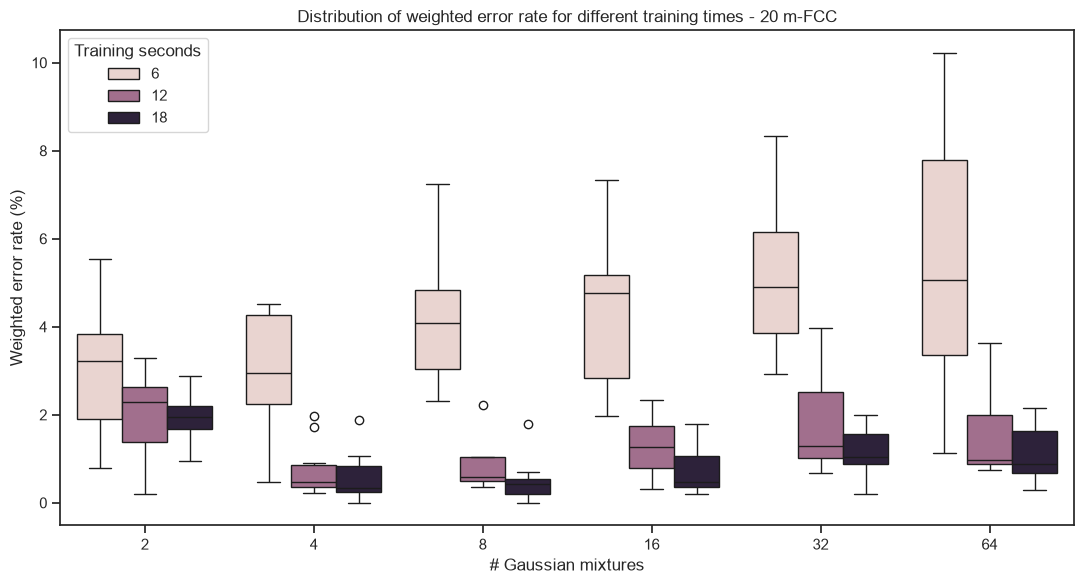

In [11]:
# Summarise the WER of the ten repeats per condition, and draw its distribution.
wer_summary = (
    wer_results
    .groupby(["training_seconds_target", "n_components"], as_index=False)
    .agg(WER_mean=("WER", "mean"), WER_std=("WER", "std"), WER_min=("WER", "min"), WER_max=("WER", "max"))
)
for col in ["WER_mean", "WER_std", "WER_min", "WER_max"]:
    wer_summary[col + "_percent"] = wer_summary[col] * 100

display(wer_summary[[
    "training_seconds_target", "n_components", "WER_mean_percent", "WER_std_percent",
    "WER_min_percent", "WER_max_percent"
]].round(3))

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=wer_results, x="n_components", y="WER_percent", hue="training_seconds_target", ax=ax)
ax.set(
    title="Distribution of weighted error rate for different training times - 20 m-FCC",
    xlabel="# Gaussian mixtures",
    ylabel="Weighted error rate (%)",
)
ax.legend(title="Training seconds")
plt.tight_layout()
plt.show()

`[OBSERVED]` More training audio lowers the mean WER at **every** model order: the 12-second value is
below the 6-second one, and the 18-second value below the 12-second one, for each of the six values
of M.

`[OBSERVED]` With **6 seconds** the error rises with the model order, from 3.000 % at M=2 and 2.918 %
at M=4 to **5.630 % at M=64**, where the ten repeats also scatter most (from 1.135 % to 10.220 %).

`[OBSERVED]` With 12 and 18 seconds the error falls sharply from M=2 to M=4 (2.069 % to 0.748 % at
12 s, 1.889 % to 0.572 % at 18 s), reaches its lowest at **M=4 (12 s) and M=8 (18 s)**, and rises again
for larger mixtures: 12 s gives 1.779 % at M=32 and 1.528 % at M=64.

`[PAPER]` Section 4.1 says the error falls from 2 to 16 components and levels off at 32 and 64, and
that with 6 seconds it degrades as the model order grows. The 6-second behaviour is reproduced. For
12 and 18 seconds the error here does not level off: it **has its minimum at a small M and rises
afterwards**.

`[OBSERVED]` The difference between neighbouring orders is often smaller than the spread between
repeats. At 12 s, M=4 and M=8 give 0.748 % and 0.831 % with standard deviations of 0.613 and 0.558.

`[INFERENCE]` With ten repeats, M=4 and M=8 cannot be told apart at 12 seconds, and the same holds for
the neighbouring pairs at the lowest end of the 18-second column. The cause of the rise at large M
cannot be isolated from these data: the reconstructed filter bank, the different species set and the
frame rate (next section) are all candidates, and none is tested here.

## 12. How much training data a condition really is

**What this section asks, and why it matters.** The article describes its training conditions by
the number of feature vectors, not only by seconds. If this replication feeds each model twice
as many vectors for the same seconds, the two are not training on the same amount of information,
and any difference in how the error moves with the model order might come from there.

`[PAPER]` Section 4.1: *"6, 12, 18 seconds of frog-call corresponding to 600, 1200 and 12800
12-dimensional mel-cepstral feature vectors"*, as printed.

In [12]:
# Compare the training frames each condition actually used with the vector counts printed in the article.
PAPER_VECTORS = {6: 600, 12: 1200, 18: 12800}

frames_table = (
    per_species_results[per_species_results.n_components == N_COMPONENTS_GRID[0]]
    .groupby("training_seconds_target")
    .agg(mean_training_seconds=("training_seconds_actual", "mean"),
         mean_training_frames=("training_frames", "mean"))
)
frames_table["frames_per_second"] = frames_table.mean_training_frames / frames_table.mean_training_seconds
frames_table["paper_vectors_as_printed"] = frames_table.index.map(PAPER_VECTORS)
frames_table["ratio_to_paper"] = frames_table.mean_training_frames / frames_table.paper_vectors_as_printed
display(frames_table.round(2))

,mean_training_seconds,mean_training_frames,frames_per_second,paper_vectors_as_printed,ratio_to_paper
training_seconds_target,,,,,
6,6.25,1210.37,193.72,600,2.02
12,12.27,2378.47,193.77,1200,1.98
18,18.29,3543.96,193.75,12800,0.28


`[OBSERVED]` The replication trains each model on about **twice the vectors the article's counts
imply**: 1210 frames against 600 for 6 seconds (ratio 2.02) and 2378 against 1200 for 12 seconds
(ratio 1.98). It produces **193.7 frames per second**, while 600 vectors for 6 seconds is 100 per
second.

`[PAPER]` For 18 seconds the article prints **12800**, which is not on the same scale as 600 and 1200.

`[INFERENCE]` A value of 1800 would continue the pattern of 600 and 1200, so 12800 is most likely a
misprint. This is the same observation as in notebook 02, where the 75 % frame overlap that doubles
the frame rate was identified. The two sides therefore compare equal *seconds* of audio, not equal
numbers of vectors.

## 13. Do the fits converge?

**What this section asks, and why it matters.** EM stops either because the likelihood stopped
improving or because it hit the iteration cap. A model that stopped on the cap is not the
maximum-likelihood model the article describes, and the larger mixtures are the ones most likely
to do it. If many fits did, the error of the larger model orders would be partly an artefact of the
cap.

In [13]:
# Count, per number of components, how many fits converged and how close they came to the iteration cap.
convergence = (
    per_species_results.groupby("n_components")
    .agg(fits=("converged", "size"), converged=("converged", "sum"),
         mean_iterations=("n_iter", "mean"), max_iterations=("n_iter", "max"))
)
convergence["converged_percent"] = convergence.converged / convergence.fits * 100
convergence["at_iteration_cap"] = per_species_results[per_species_results.n_iter >= MAX_ITER].groupby("n_components").size()
convergence["at_iteration_cap"] = convergence["at_iteration_cap"].fillna(0).astype(int)
display(convergence.round(2))
print("iteration cap:", MAX_ITER)

,fits,converged,mean_iterations,max_iterations,converged_percent,at_iteration_cap
n_components,,,,,,
2,270,270,11.36,39,100.0,0
4,270,270,16.78,59,100.0,0
8,270,270,20.87,52,100.0,0
16,270,270,25.41,67,100.0,0
32,270,270,28.19,56,100.0,0
64,270,270,27.43,58,100.0,0


iteration cap: 100


`[OBSERVED]` **All 1620 fits converged**, 270 at each model order, and none stopped on the cap of 100
iterations. The slowest fit needed 67 iterations (at M=16), and the mean number of iterations grows
from 11.36 at M=2 to 28.19 at M=32.

`[INFERENCE]` The rise in error at large M seen above is not an artefact of EM being cut short by the
iteration cap.

## 14. Recordings shared between training and validation

**What this section asks, and why it matters.** Splitting by call keeps the frames of one call
apart, but several calls come from the same recording, with the same microphone position, background
noise and often the same individual. If most validation calls have a sibling from their recording in
the training set, the error measured here is closer to *recognising a known recording* than to
*recognising the species in a new one*, and every later choice made with it inherits that.

`[PAPER]` The article selects its training and validation sets by random segment selection and
does not say whether segments of one recording may fall on both sides.

In [14]:
# For each species and duration: the share of validation calls whose recording also supplied training calls.
shared = per_species_results[per_species_results.n_components == N_COMPONENTS_GRID[0]].copy()
shared["shared_percent"] = shared.n_validation_shared_wav / shared.n_validation_calls * 100

shared_table = (
    shared.groupby(["code", "species", "training_seconds_target"]).shared_percent.mean()
    .unstack("training_seconds_target")
    .round(1)
)
shared_table.insert(0, "source_wavs", shared.groupby(["code", "species"]).n_wavs.first().to_numpy())
shared_table.columns = [c if isinstance(c, str) else f"shared % at {c} s" for c in shared_table.columns]
display(shared_table)

overall = shared.groupby("training_seconds_target").apply(
    lambda g: g.n_validation_shared_wav.sum() / g.n_validation_calls.sum() * 100, include_groups=False)
print("validation calls sharing a recording with training, all species pooled (%):")
print(overall.round(1).to_string())

,,source_wavs,shared % at 6 s,shared % at 12 s,shared % at 18 s
code,species,,,,
f01,Boana alfaroi,5,93.0,100.0,100.0
f02,Dendropsophus bifurcus,10,79.3,94.5,97.7
f03,Boana cinerascens,8,78.1,90.8,95.1
f04,Pristimantis conspicillatus,9,86.7,95.5,96.2
f05,Leptodactylus discodactylus,3,98.6,100.0,100.0
f06,Osteocephalus fuscifacies,5,93.5,98.5,100.0
f07,Boana lanciformis,7,77.6,92.5,96.5
f08,Rhinella margaritifera,7,62.7,87.9,93.2
f10,Engystomops petersi,12,76.5,89.1,97.2


validation calls sharing a recording with training, all species pooled (%):
training_seconds_target
6     84.2
12    94.1
18    97.4


`[OBSERVED]` Across all species, **84.2 %** of the validation calls of the 6-second condition come from
a recording that also supplied training calls, **94.1 %** for 12 seconds and **97.4 %** for 18 seconds.
At 12 seconds the share lies between 87.9 % (`f08`) and 100.0 % (`f01` and `f05`). `f05` has only 3
source recordings and `f01` 5.

`[INFERENCE]` The error measured here is closer to *recognising a species in a recording it has
already heard part of* than to recognising it in a new recording. A selection that keeps whole
recordings on one side would be needed to measure the second, and the numbers in this notebook should
not be read as that.

`[INFERENCE]` The share grows with the training duration, as does the improvement of the error, so part
of the gain from more audio may come from covering more recordings and not only from having more
frames. These data do not separate the two.

## 15. Reproduce the structure of Table 2

**What this section asks, and why it matters.** Table 2 is the article's per-species view: which
species are hard, and how each behaves as the number of Gaussians grows. It is the one place where
the article's 20 m-FCC results can be compared with this replication's, species by species.

`[PAPER]` Table 2 reports the per-species error for the **12-second** condition with **20 m-FCC**.
The species set differs here (`f06` present, `f09` absent), so the table is comparable in
structure, not number for number.

In [15]:
# Average the per-species error of the 12-second condition over the ten repeats, by number of components.
table2_replication = (
    per_species_results[per_species_results["training_seconds_target"] == 12]
    .groupby(["code", "species", "n_components"])["error_rate"]
    .mean()
    .mul(100)
    .unstack("n_components")
    .reindex(columns=N_COMPONENTS_GRID)
    .round(3)
)
table2_replication.columns = [f"M={m}" for m in table2_replication.columns]
display(table2_replication)

,,M=2,M=4,M=8,M=16,M=32,M=64
code,species,,,,,,
f01,Boana alfaroi,0.000,0.000,0.000,0.000,0.000,0.000
f02,Dendropsophus bifurcus,11.129,2.538,2.539,3.099,3.238,2.793
f03,Boana cinerascens,6.844,3.550,3.285,3.621,3.887,3.956
f04,Pristimantis conspicillatus,0.000,0.128,0.446,1.403,0.639,0.702
f05,Leptodactylus discodactylus,0.197,0.000,0.000,0.033,0.033,0.000
f06,Osteocephalus fuscifacies,0.000,0.000,0.000,0.370,0.000,0.000
f07,Boana lanciformis,0.000,0.000,0.241,0.361,1.455,0.602
f08,Rhinella margaritifera,0.000,0.479,0.720,2.248,6.548,4.897
f10,Engystomops petersi,0.453,0.035,0.244,0.174,0.209,0.801


`[OBSERVED]` `f01` is never misidentified. `f02` falls from 11.129 % at M=2 to 2.538 % at M=4, and
`f03` stays between 3.285 % and 6.844 % at every order. `f08` is perfect at M=2 and then rises to
**6.548 % at M=32** and 4.897 % at M=64.

`[INFERENCE]` The hardest species are `f02`, `f03` and `f08`, and for `f08` a larger mixture makes
identification worse. A mixture with many components fitted on few, highly similar frames can model
one recording's conditions, which is compatible with the shared-recording finding but not proved by
it.

### Published Table 2 values, and the difference

`[PAPER]` The article's nine-species experiment excludes `f06` and includes `f09`. The published
values are reproduced below as a transparent reference; this replication is not forced to match
them. A difference is *replication minus paper*, in percentage points, and is empty (`NaN`) where
the article reports no value for the species.

In [16]:
# Type the published Table 2 and subtract it from the replication, species by species.
PAPER_TABLE2_PERCENT = pd.DataFrame(
    {
        "M=2":  [0.0, 9.4, 0.4, 0.5, 0.3, 7.8, 11.7, 4.7, 0.2],
        "M=4":  [0.0, 6.7, 0.2, 0.6, 0.2, 3.4, 6.1, 3.0, 0.0],
        "M=8":  [0.0, 2.7, 0.2, 0.3, 0.3, 1.8, 5.2, 3.7, 0.0],
        "M=16": [0.0, 0.8, 0.1, 0.3, 0.1, 1.6, 4.2, 3.0, 0.0],
        "M=32": [0.0, 0.9, 0.1, 0.3, 0.1, 1.3, 4.1, 3.4, 0.0],
        "M=64": [0.0, 0.8, 0.2, 0.3, 0.2, 1.6, 3.2, 3.0, 0.0],
    },
    index=["f01", "f02", "f03", "f04", "f05", "f07", "f08", "f09", "f10"],
)
PAPER_TABLE2_PERCENT.index.name = "code"
print("Published Table 2 (error %, 12 s, 20 m-FCC):")
display(PAPER_TABLE2_PERCENT)

replication_by_code = table2_replication.reset_index(level="species", drop=True)
difference = (replication_by_code - PAPER_TABLE2_PERCENT.reindex(replication_by_code.index)).round(3)
print("Replication minus paper, percentage points:")
display(difference)

# Averaged over the species both tables report, which is the fair single number per model order.
common = PAPER_TABLE2_PERCENT.index.intersection(replication_by_code.index)
print("Mean over the", len(common), "species in both tables (error %):")
display(pd.DataFrame({"paper": PAPER_TABLE2_PERCENT.loc[common].mean(),
                      "replication": replication_by_code.loc[common].mean()}).round(3).T)

Published Table 2 (error %, 12 s, 20 m-FCC):


,M=2,M=4,M=8,M=16,M=32,M=64
code,,,,,,
f01,0.0,0.0,0.0,0.0,0.0,0.0
f02,9.4,6.7,2.7,0.8,0.9,0.8
f03,0.4,0.2,0.2,0.1,0.1,0.2
f04,0.5,0.6,0.3,0.3,0.3,0.3
f05,0.3,0.2,0.3,0.1,0.1,0.2
f07,7.8,3.4,1.8,1.6,1.3,1.6
f08,11.7,6.1,5.2,4.2,4.1,3.2
f09,4.7,3.0,3.7,3.0,3.4,3.0
f10,0.2,0.0,0.0,0.0,0.0,0.0


Replication minus paper, percentage points:


,M=2,M=4,M=8,M=16,M=32,M=64
code,,,,,,
f01,0.000,0.000,0.000,0.000,0.000,0.000
f02,1.729,-4.162,-0.161,2.299,2.338,1.993
f03,6.444,3.350,3.085,3.521,3.787,3.756
f04,-0.500,-0.472,0.146,1.103,0.339,0.402
f05,-0.103,-0.200,-0.300,-0.067,-0.067,-0.200
f06,NaN,NaN,NaN,NaN,NaN,NaN
f07,-7.800,-3.400,-1.559,-1.239,0.155,-0.998
f08,-11.700,-5.621,-4.480,-1.952,2.448,1.697
f10,0.253,0.035,0.244,0.174,0.209,0.801


Mean over the 8 species in both tables (error %):


,M=2,M=4,M=8,M=16,M=32,M=64
paper,3.788,2.150,1.312,0.888,0.850,0.788
replication,2.328,0.841,0.934,1.367,2.001,1.719


`[OBSERVED]` `f03` is **worse than the article at every model order**, by 3.085 to 6.444 percentage
points. `f02` is better than the article at M=4 (4.162 points lower) and M=8 (0.161 lower) and worse at the
other four orders. `f08` is lower than the article from M=2 to M=16 and higher at M=32 and M=64, and
`f07` is lower at every order except M=32.

`[OBSERVED]` Averaged over the 8 species present in both tables, the article's error falls steadily
from 3.788 % at M=2 to **0.788 % at M=64**. The replication falls from 2.328 % to a minimum of
**0.841 % at M=4**, then rises to 1.719 % at M=64.

`[INFERENCE]` The two corpora differ in one species, in their recordings, and in the frame rate, so a
numerical gap is not by itself a failure to replicate. What differs in *shape* is where the minimum
lies, and that is a result of this replication, reported as it is.

## 16. Best condition, and the article's headline figure

**What this section asks, and why it matters.** The article picks its model order (`M = 64`) because
it gave the lowest average error, and reports **0.9 %** for 12 seconds and 64 Gaussians with 20 m-FCC
in its abstract. This replication has to find its own optimum rather than assume the same one, and
state plainly how far its own 12 s, `M = 64` figure is from the published one.

`[PAPER]` Abstract: *"With 64 Gaussians and 12 seconds of training time, the classifier achieved an
average weighted error rate of 0.9% … as compared to 3% with MFCC and 1.8% with PLP features."*
Section 4.1: at least 12 seconds and more than 32 components are needed; with 6 seconds the error
rises as the model order grows.

In [17]:
# Find the lowest mean WER, set it against the published figures, and lay out the WER by model order.
best = wer_summary.sort_values(["WER_mean", "training_seconds_target", "n_components"]).iloc[0]
print("Lowest mean WER in this replication:")
print(f"  training duration : {int(best.training_seconds_target)} s")
print(f"  components        : {int(best.n_components)}")
print(f"  mean WER          : {best.WER_mean_percent:.3f}%")
print(f"  std               : {best.WER_std_percent:.3f}%")

at_12_s = wer_summary[wer_summary.training_seconds_target == 12].set_index("n_components")
best_12 = at_12_s.WER_mean_percent.idxmin()
print("\n12 s, 64 components:")
print(f"  replication (20 m-FCC) : {at_12_s.loc[64, 'WER_mean_percent']:.3f}%")
print("  paper, 20 m-FCC        : 0.9%")
print("  paper, 12 MFCC         : 3%")
print(f"12 s, best model order here: M={best_12} at {at_12_s.loc[best_12, 'WER_mean_percent']:.3f}%")

print("\nMean WER (%) by model order (rows) and training seconds (columns):")
display(wer_summary.pivot(index="n_components", columns="training_seconds_target",
                          values="WER_mean_percent").round(3))

Lowest mean WER in this replication:
  training duration : 18 s
  components        : 8
  mean WER          : 0.501%
  std               : 0.502%

12 s, 64 components:
  replication (20 m-FCC) : 1.528%
  paper, 20 m-FCC        : 0.9%
  paper, 12 MFCC         : 3%
12 s, best model order here: M=4 at 0.748%

Mean WER (%) by model order (rows) and training seconds (columns):


training_seconds_target,6,12,18
n_components,,,
2,3.000,2.069,1.889
4,2.918,0.748,0.572
8,4.166,0.831,0.501
16,4.347,1.257,0.715
32,5.143,1.779,1.178
64,5.630,1.528,1.121


`[OBSERVED]` The lowest mean WER in the replication is **0.501 % at 18 seconds and M=8**. At the
article's headline setting (12 seconds, M=64) the replication gives **1.528 %**, between the article's
0.9 % for 20 m-FCC and its 3 % for 12 MFCC. The best order at 12 seconds is M=4, with 0.748 %.

`[OBSERVED]` The lowest mean WER falls at **M=4 for 6 and 12 seconds and M=8 for 18 seconds**, never at
M=64. The article's choice of M=64 is therefore not supported as the optimum by this experiment.

`[INFERENCE]` Because the recordings are shared across the split (section 14), these error rates are
optimistic, and whether a small M would still win on recordings never seen in training is untested here.
It is a question for any later selection of the model order.

## 17. Save the experiment outputs

**What this section asks, and why it matters.** The grid takes minutes to run. Its tables are
written so that the analysis can be inspected without retraining, and so that later work can read
the numbers it needs. The fitted mixtures themselves are not stored: there are 1620 of them, and
each can be regenerated from its seed.

In [18]:
# Write the experiment tables, reload one to check it, and list only the files written here.
RESULTS_DIR = PROCESSED_DIR / "gmm_parameter_investigation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUTS = {
    "per_species_results.csv": per_species_results,
    "wer_by_repeat.csv": wer_results,
    "wer_summary.csv": wer_summary,
    "call_predictions.csv": call_predictions,
}
for name, table in OUTPUTS.items():
    table.to_csv(RESULTS_DIR / name, index=False)
table2_replication.to_csv(RESULTS_DIR / "table2_replication.csv")

reloaded = pd.read_csv(RESULTS_DIR / "per_species_results.csv")
print("per_species_results.csv reloads with the same shape:", reloaded.shape == per_species_results.shape)

print("\nwritten to", RESULTS_DIR.relative_to(REPO_ROOT).as_posix())
for name in [*OUTPUTS, "table2_replication.csv"]:
    print(f"  {name:<28} {(RESULTS_DIR / name).stat().st_size / 1e6:>8.2f} MB")

per_species_results.csv reloads with the same shape: True

written to data/processed/gmm_parameter_investigation
  per_species_results.csv          0.17 MB
  wer_by_repeat.csv                0.01 MB
  wer_summary.csv                  0.00 MB
  call_predictions.csv            15.42 MB
  table2_replication.csv           0.00 MB


## 18. Conclusions and limitations

**What this notebook delivers.** The article's GMM identification experiment, run on the 20 m-FCC
features of notebook 02: 180 conditions (3 training durations × 6 model orders × 10 random selections)
with one diagonal GMM per species in each, scored by the mean frame log-likelihood of whole calls. The
tables of error per species, per repeat and per call are written to `data/processed/gmm_parameter_investigation`.
The code that builds the splits, fits the mixtures and scores the calls is in `frog_presence.gmm`, with
tests, and is the same procedure any later notebook has to use.

**What was found.** More training audio lowers the error at every model order, and the 6-second
behaviour the article describes is reproduced. The model order that minimises the error here is small
(M=4 or M=8), not the article's M=64, and the headline 12-second, M=64 error is 1.528 % against the
article's 0.9 %. All fits converged, so this is not an effect of the iteration cap.

**Decisions taken here, which the article does not state.**

1. **A species takes part when it holds more than 18 seconds of calls**, which keeps nine species.
2. **Whole calls are shuffled and taken until the duration is reached or exceeded**; calls are never cut.
3. **Ten reproducible random selections** replace the article's "10-fold cross-validation with random
   segment selection", which is not described precisely enough to reproduce.
4. **One split is shared by all six model orders** within a duration and a repeat.
5. **scikit-learn's defaults** for the variance floor, the iteration cap and the tolerance, none of which
   the article reports.
6. **The experiment runs on the 20 m-FCC features**, the setting of Table 2, not on the 12 MFCC of Figure 8.

**Limitations.**

- **Figure 8 is not reproduced.** The article draws it with 12 MFCC features, which are not built in this
  notebook. The plot here is a model-order grid on 20 m-FCC.
- **Training and validation share recordings.** Between 84.2 % and 97.4 % of validation calls come from a
  recording that also supplied training calls, so the errors above are optimistic with respect to unseen
  recordings. The article's own selection probably has the same property, but it does not say so.
- **Twice the vectors per second of audio.** The replication yields about 194 frames per second and the
  article's counts imply 100, so equal seconds do not mean equal numbers of vectors.
- **The m-FCC filter bank is an estimate** (notebook 02), and every error here carries that.
- **The species set differs from the article's**: `f06` is present and `f09` cannot be modelled.
- **Ten selections separate neighbouring model orders poorly**; the lowest orders are not distinguishable
  from each other at the lowest errors.
- **The 1620 fitted mixtures are not stored**, only the tables; each can be regenerated from its seed.